In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
# Load CSV
teams_post = pd.read_csv("../basketballPlayoffs/teams_post.csv")

In [19]:
# Calculate the win-loss difference for each team in each year
teams_post['win_loss_diff'] = teams_post['W'] - teams_post['L']

# Find the team with the highest win-loss difference for each year
best_team_per_year = teams_post.loc[teams_post.groupby('year')['win_loss_diff'].idxmax()][['year', 'tmID', 'W', 'L', 'win_loss_diff']]
best_team_per_year = best_team_per_year.sort_values(by='year').reset_index(drop=True)

print(best_team_per_year)


   year tmID  W  L  win_loss_diff
0     1  HOU  6  0              6
1     2  LAS  6  1              5
2     3  LAS  6  0              6
3     4  DET  6  2              4
4     5  SEA  6  2              4
5     6  SAC  7  1              6
6     7  DET  7  3              4
7     8  PHO  7  2              5
8     9  DET  7  2              5
9    10  PHO  7  4              3


In [20]:
# Count the number of appearances for each team across all years
team_appearances = teams_post.groupby('tmID').size().reset_index(name='appearances')

# Sort by appearances in descending order to find teams with the most appearances
team_appearances = team_appearances.sort_values(by='appearances', ascending=False).reset_index(drop=True)

print(team_appearances)


   tmID  appearances
0   LAS            9
1   SAC            8
2   DET            7
3   NYL            7
4   SEA            7
5   CON            6
6   HOU            6
7   IND            6
8   WAS            5
9   SAS            3
10  CLE            3
11  CHA            3
12  PHO            3
13  UTA            2
14  MIN            2
15  ORL            1
16  MIA            1
17  ATL            1


In [21]:
# Identify the team with the highest win-loss difference for each year
yearly_winners = teams_post.loc[teams_post.groupby('year')['win_loss_diff'].idxmax()][['year', 'tmID', 'win_loss_diff']]

# Count the number of times each team has been a "winner" across all years
team_win_counts = yearly_winners['tmID'].value_counts().reset_index()
team_win_counts.columns = ['tmID', 'win_count']

# Count the number of times each team has won and collect the years
team_win_counts = yearly_winners.groupby('tmID').agg(
    win_count=('year', 'size'),
    win_years=('year', lambda x: list(x))
).reset_index()

# Sort by the number of wins in descending order
team_win_counts = team_win_counts.sort_values(by='win_count', ascending=False).reset_index(drop=True)

print(team_win_counts)


  tmID  win_count  win_years
0  DET          3  [4, 7, 9]
1  LAS          2     [2, 3]
2  PHO          2    [8, 10]
3  HOU          1        [1]
4  SAC          1        [6]
5  SEA          1        [5]


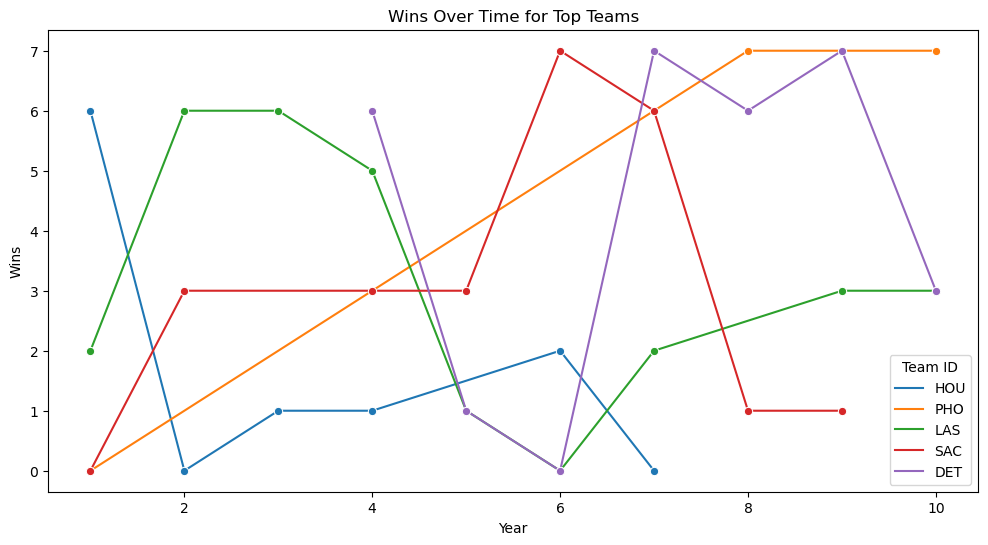

In [22]:
# Filter to select top teams by total wins (modify as needed for top 5 or 10)
top_teams = team_win_counts['tmID'].head(5)  # Assuming `team_win_counts` from previous analysis
top_teams_data = teams_post[teams_post['tmID'].isin(top_teams)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=top_teams_data, x='year', y='W', hue='tmID', marker="o")
plt.xlabel("Year")
plt.ylabel("Wins")
plt.title("Wins Over Time for Top Teams")
plt.legend(title="Team ID")
plt.show()

In [23]:
# Calculate win percentage for each row
teams_post['win_pct'] = teams_post['W'] / (teams_post['W'] + teams_post['L'])

# Create a pivot table with year as rows and team ID as columns, displaying win_pct
win_pct_pivot = team_stats.pivot(index="year", columns="tmID", values="win_pct")

NameError: name 'team_stats' is not defined